In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [3]:
import os
import cv2
import numpy as np

# Main dataset folder
ImagesPath = '/content/drive/MyDrive/train'

# Actual class folder names
ClassNames = ['o', 'R']

# Correct labels
ClassLabels = {
    'o': 0,
    'R': 1
}

ImagesArray = []
Labels = []

W, H = 100, 120

for ClassName in ClassNames:

    ClassPath = os.path.join(ImagesPath, ClassName)

    for img_name in os.listdir(ClassPath):

        img_path = os.path.join(ClassPath, img_name)

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

        if img is None:
            continue

        img = cv2.resize(img, (H, W))

        img = img.reshape(W, H, 1)

        ImagesArray.append(img)
        Labels.append(ClassLabels[ClassName])

X = np.array(ImagesArray, dtype='float32') / 255.0

y = np.array(Labels, dtype='int32')

print("Images shape:", X.shape)
print("Labels shape:", y.shape)

print("Organic images:", np.sum(y == 0))
print("Recyclable images:", np.sum(y == 1))

Images shape: (3999, 100, 120, 1)
Labels shape: (3999,)
Organic images: 1999
Recyclable images: 2000


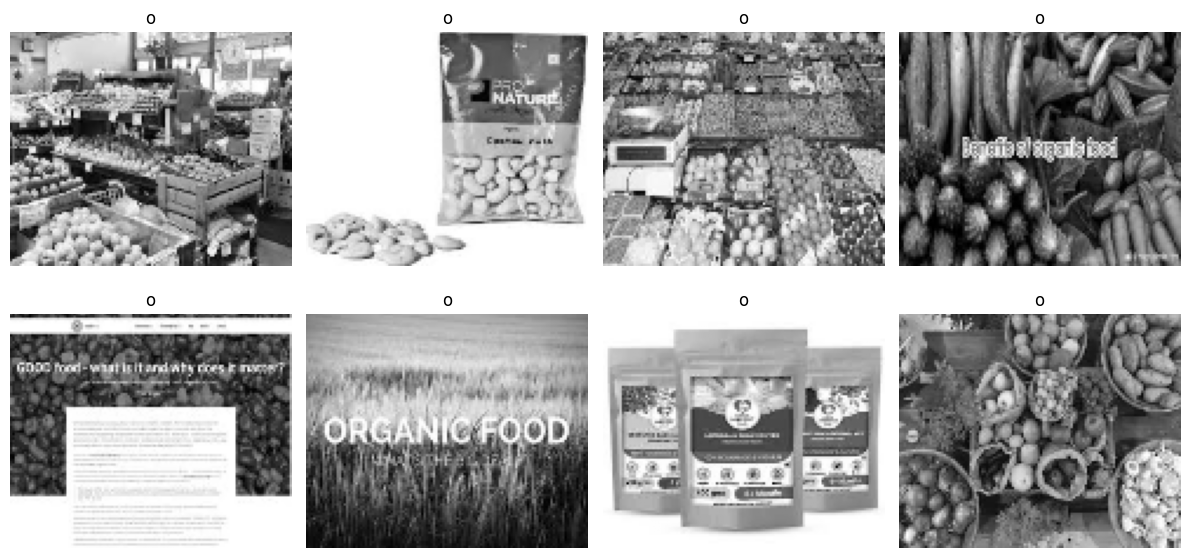

In [4]:
plt.figure(figsize=(12, 6))
for i in range(min(8, len(X))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(X[i].squeeze(), cmap='gray')
    plt.title(ClassNames[y[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=44, shuffle=True, stratify=y
)

print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (2999, 100, 120, 1)
X_test: (1000, 100, 120, 1)
y_train: (2999,)
y_test: (1000,)


In [21]:
KerasModel = keras.models.Sequential([

    keras.layers.Input(shape=(W, H, 1)),

    # Data Augmentation
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.05),
    keras.layers.RandomZoom(0.1),

    # CNN layers
    keras.layers.Conv2D(
        32, (3, 3),
        activation='relu',
        padding='same'
    ),

    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.BatchNormalization(),

    keras.layers.Conv2D(
        32, (3, 3),
        activation='relu',
        padding='same'
    ),

    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.BatchNormalization(),

    keras.layers.Flatten(),

    keras.layers.Dense(128, activation='relu'),

    keras.layers.Dropout(0.3),

    keras.layers.Dense(1, activation='sigmoid')

])

KerasModel.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 100, 120, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 100, 120, 1)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 100, 120, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 100, 120, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 50, 60, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 50, 60, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 50, 60, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 25, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 25, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 24000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,072,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,082,081 (11.76 MB)

 Trainable params: 3,081,953 (11.76 MB)

 Non-trainable params: 128 (512.00 B)

In [33]:
KerasModel.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Stop training when validation loss stops improving
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Reduce learning rate when validation loss stops improving
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

history = KerasModel.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=20,
    validation_split=0.10,
    shuffle=True,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/30
135/135 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.7258 - loss: 0.5507 - val_accuracy: 0.7133 - val_loss: 1.0667 - learning_rate: 0.0010
Epoch 2/30
135/135 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.7132 - loss: 0.5637 - val_accuracy: 0.5267 - val_loss: 4.7596 - learning_rate: 0.0010
Epoch 3/30
135/135 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.7358 - loss: 0.5264 - val_accuracy: 0.5333 - val_loss: 1.6980 - learning_rate: 0.0010
Epoch 4/30
135/135 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.7562 - loss: 0.4902 - val_accuracy: 0.7200 - val_loss: 0.9369 - learning_rate: 5.0000e-04
Epoch 5/30
135/135 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.7466 - loss: 0.5011 - val_accuracy: 0.7267 - val_loss: 1.4663 - learning_rate: 5.0000e-04
Epoch 6/30
135/135 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.7481 - loss: 0.5051 - val_accuracy: 0.7133 - val_loss: 0.9898 - learning_rate: 5.0000e-04
Epoch 7/30
135/135 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.753

In [34]:
test_loss, test_acc = KerasModel.evaluate(X_test, y_test, verbose=1)
print('Test Loss:', test_loss)
print('Test Accuracy:', test_acc)

y_prob = KerasModel.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype('int32')

print('Accuracy Score:', accuracy_score(y_test, y_pred))
print(classification_report(
    y_test, y_pred, labels=[0, 1], target_names=ClassNames, zero_division=0
))
print('Confusion matrix:\n', confusion_matrix(y_test, y_pred))

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7460 - loss: 0.6243
Test Loss: 0.6242963671684265
Test Accuracy: 0.7459999918937683
Accuracy Score: 0.746
              precision    recall  f1-score   support

           o       0.71      0.83      0.77       500
           R       0.80      0.66      0.72       500

    accuracy                           0.75      1000
   macro avg       0.75      0.75      0.74      1000
weighted avg       0.75      0.75      0.74      1000

Confusion matrix:
 [[417  83]
 [171 329]]


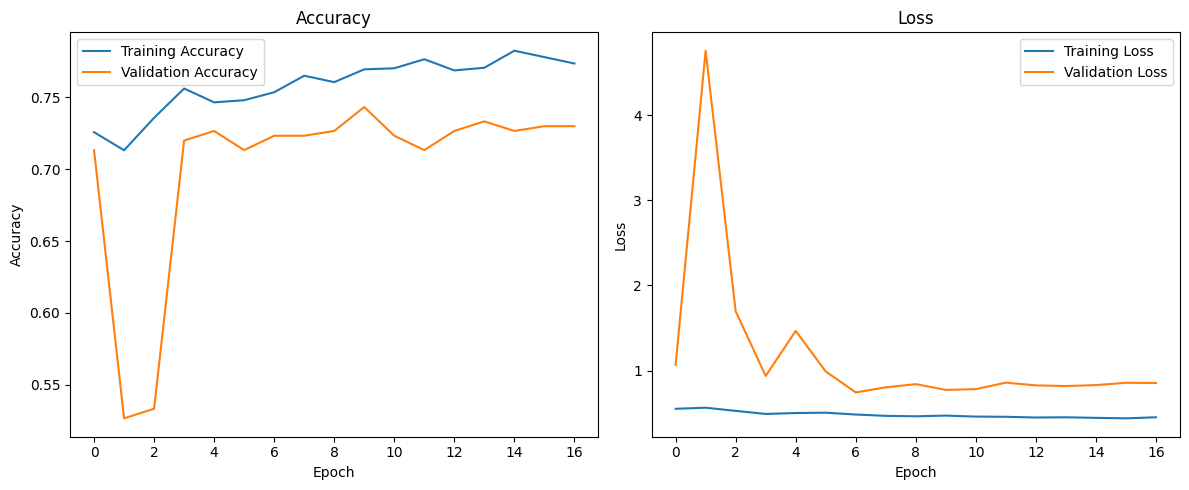

In [35]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Accuracy'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Loss'); plt.legend()
plt.tight_layout()
plt.show()


In [36]:
def PredictImage(image_path):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f'Could not read image: {image_path}')

    img = cv2.resize(img, (H, W))
    img = img.astype('float32') / 255.0
    img = img.reshape(1, W, H, 1)

    probability_rec = float(KerasModel.predict(img, verbose=0)[0][0])
    predicted_label = 1 if probability_rec >= 0.5 else 0

    print('Prediction:', ClassNames[predicted_label])
    print(f'Probability of rec: {probability_rec:.4f}')

    plt.imshow(img[0].squeeze(), cmap='gray')
    plt.title(f'Predicted: {ClassNames[predicted_label]}')
    plt.axis('off')
    plt.show()


Prediction: o
Probability of rec: 0.4975


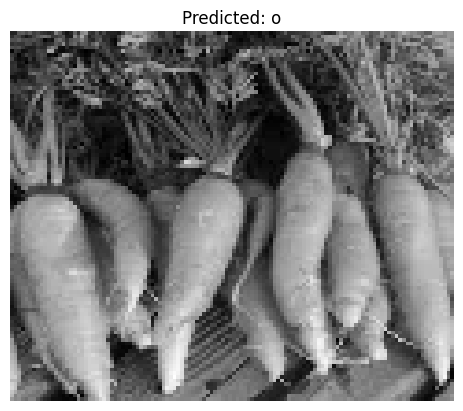

In [37]:
 PredictImage('/content/drive/MyDrive/TEST/O/O_12568.jpg')


Prediction: R
Probability of rec: 0.9826


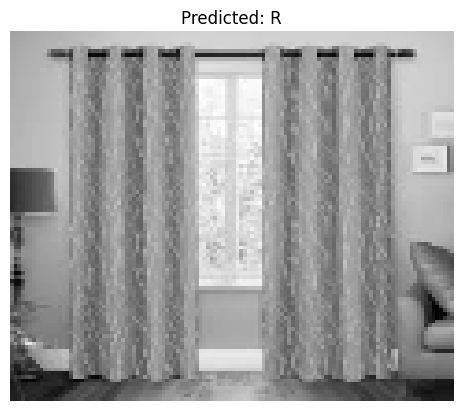

In [38]:
 PredictImage('/content/drive/MyDrive/TEST/R/R_10013.jpg')


Prediction: R
Probability of rec: 0.6749


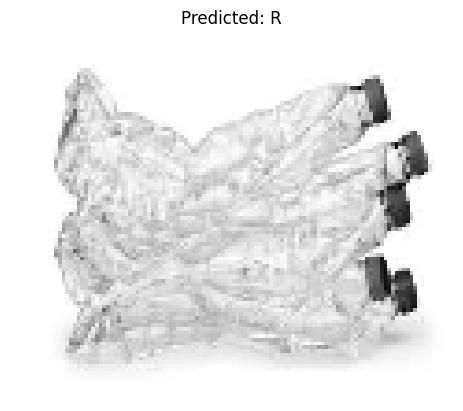

In [41]:
PredictImage('/content/drive/MyDrive/TEST/R/R_17.jpg')